# FarmTech Solutions — Fase 6 — Grupo 21
## Entrega 1: detecção de bananas e garrafas PET com YOLOv5

**Autor desta contribuição:** Lucas Carvalho Cordeiro — **RM 570388**.  
**Equipe:** Lucas (YOLO customizada e integração), Larissa (dados e documentação), Elton (YOLO padrão e comparação) e Matheus (CNN do zero e vídeo).  
**Execução registrada:** 12/10/2026, Google Colab com GPU Tesla T4.

O objetivo é demonstrar ao cliente fictício da FarmTech um sistema que reconhece bananas e garrafas PET e desenha caixas em volta dos objetos. Usamos a YOLOv5s com pesos pré-treinados e ajustamos o modelo para as duas classes do grupo. Esta contribuição reúne a **Entrega 1** e fornece resultados para a comparação da Entrega 2. A YOLO padrão, a CNN e a comparação completa serão integradas a partir das contribuições dos colegas.

A sequência é: conferir os dados e as marcações, preparar o ambiente, treinar dois experimentos independentes, escolher pela validação e avaliar o modelo escolhido no teste reservado. As células de código e suas saídas foram preservadas do notebook executado pelo autor; a revisão acrescentou identificação, organização e explicações.

**Dados e pesos:** [Google Drive do grupo](https://drive.google.com/drive/folders/1T-mHMYGu8Nj33VuK808TOb8hT5D6Q5OT). As marcações foram preparadas pelo grupo no Make Sense IA. Há 40 fotos de cada classe, separadas em 32 para treino, 4 para validação e 4 para teste. Cada foto contém uma classe alvo, mas pode conter vários objetos dessa classe.

| Classe | ID | Treino | Validação | Teste | Total |
| --- | ---: | ---: | ---: | ---: | ---: |
| Banana | 0 | 32 | 4 | 4 | 40 |
| Garrafa PET | 1 | 32 | 4 | 4 | 40 |
| **Total** | | **64** | **8** | **8** | **80** |

### Como abrir e executar

1. Abra o notebook no Google Colab e selecione uma GPU nas configurações do ambiente.
2. Abra o Drive do grupo e adicione um atalho da pasta **FIAP_fase6_grupo21** em **Meu Drive**. Se preferir copiar os arquivos, preserve a estrutura `dataset_yolo/organizado/images` e `labels` com as pastas `train`, `val` e `test`.
3. Execute as células na ordem e autorize a montagem do Drive. Ajuste `BASE` e `RESULTADOS` caso os caminhos da sua cópia sejam diferentes.

Uma nova execução cria pastas com novos horários. As saídas abaixo correspondem à execução de 12/10/2026. Os conjuntos usados estão identificados no [manifesto da base](https://github.com/lucas-crvlh/fase6-cap1-farmtech/blob/main/data/manifesto.csv).

## 1. Conferir a GPU

A GPU acelera os cálculos da rede. Nesta execução, o Colab disponibilizou uma Tesla T4.

In [1]:
import torch

# Confirma se o Colab disponibilizou uma GPU.
gpu_disponivel = torch.cuda.is_available()
print("GPU disponível:", gpu_disponivel)

if gpu_disponivel:
    print("Nome da GPU:", torch.cuda.get_device_name(0))

GPU disponível: True
Nome da GPU: Tesla T4


## 2. Conectar o Drive e conferir a base

Montamos o Drive para acessar a pasta compartilhada e conferimos os pares de imagens e marcações de treino, validação e teste. Montar o Drive sozinho não concede acesso aos arquivos do grupo; é preciso ter o atalho ou a cópia indicada na introdução.

In [2]:
from google.colab import drive

# Conecta o notebook ao seu Google Drive.
drive.mount("/content/drive")

Mounted at /content/drive


In [3]:
from pathlib import Path

# Caminho das imagens e marcações organizadas.
BASE = Path(
    "/content/drive/MyDrive/FIAP_fase6_grupo21/dataset_yolo/organizado"
)

if BASE.is_dir():
    print("Pasta encontrada!")

    for nome, pasta in [
        ("Treino", "train"),
        ("Validação", "val"),
        ("Teste", "test"),
    ]:
        imagens = list((BASE / "images" / pasta).glob("*.jpg"))
        marcacoes = list((BASE / "labels" / pasta).glob("*.txt"))
        print(f"{nome}: {len(imagens)} imagens e {len(marcacoes)} marcações")
else:
    print("Pasta não encontrada. Precisamos conferir o atalho e o caminho.")

Pasta encontrada!
Treino: 64 imagens e 64 marcações
Validação: 8 imagens e 8 marcações
Teste: 8 imagens e 8 marcações


## 3. Conferir as marcações

Cada marcação informa a classe do objeto e a posição de sua caixa. No formato YOLO, cada linha contém `classe, centro_x, centro_y, largura, altura`, com coordenadas entre 0 e 1.

Vamos visualizar dois exemplos de treino de cada classe para verificar se as caixas e os nomes correspondem aos objetos fotografados. Esta visualização é uma amostra, e não uma revisão visual completa de todas as caixas.

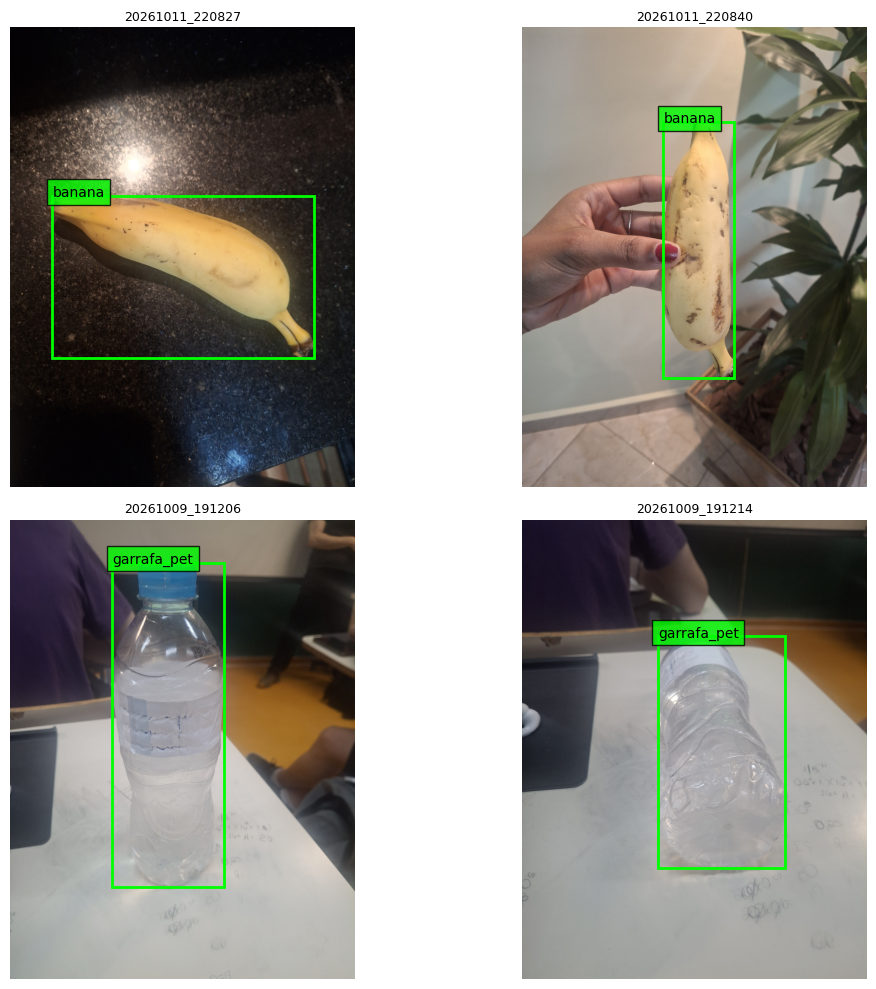

In [4]:
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

classes = {0: "banana", 1: "garrafa_pet"}
amostras = {0: [], 1: []}

# Seleciona duas imagens de treino de cada classe.
for arquivo in sorted((BASE / "labels" / "train").glob("*.txt")):
    linhas = arquivo.read_text().strip().splitlines()
    if not linhas:
        continue

    classe = int(linhas[0].split()[0])

    if classe in amostras and len(amostras[classe]) < 2:
        amostras[classe].append(arquivo)

    if all(len(lista) == 2 for lista in amostras.values()):
        break

selecionadas = amostras[0] + amostras[1]
fig, eixos = plt.subplots(2, 2, figsize=(12, 10))

for eixo, arquivo in zip(eixos.flat, selecionadas):
    caminho = BASE / "images" / "train" / f"{arquivo.stem}.jpg"
    foto = ImageOps.exif_transpose(Image.open(caminho)).convert("RGB")
    largura, altura = foto.size

    eixo.imshow(foto)

    # Transforma as marcações em caixas sobre a fotografia.
    for linha in arquivo.read_text().strip().splitlines():
        classe, x, y, w, h = map(float, linha.split())
        esquerda = (x - w / 2) * largura
        topo = (y - h / 2) * altura

        caixa = Rectangle(
            (esquerda, topo),
            w * largura,
            h * altura,
            fill=False,
            edgecolor="lime",
            linewidth=2
        )
        eixo.add_patch(caixa)
        eixo.text(
            esquerda, topo, classes[int(classe)],
            color="black",
            bbox=dict(facecolor="lime", alpha=0.8)
        )

    eixo.set_title(arquivo.stem, fontsize=9)
    eixo.axis("off")

plt.tight_layout()
plt.show()

## 4. Preparar a YOLOv5

Instalamos o código oficial e as bibliotecas necessárias. **YOLO** é uma rede que identifica a classe e a posição dos objetos em uma imagem. **YOLOv5s** é a variante pequena utilizada neste trabalho.

O código registra o commit utilizado: `f9578796b8a64889aa9e66dc06914d19f40d338e`. O registro de inferência confirma Python `3.13.15`, PyTorch `2.11.0+cu130` e GPU Tesla T4.

O instalador original abaixo clona a versão disponível no GitHub no momento da execução. Para repetir com o mesmo código de referência, após a clonagem e antes da instalação das dependências, use `git -C /content/yolov5 fetch origin f9578796b8a64889aa9e66dc06914d19f40d338e` e `git -C /content/yolov5 checkout f9578796b8a64889aa9e66dc06914d19f40d338e`. As versões completas das dependências não foram congeladas; uma execução futura pode exigir ajustes no ambiente.

Referência: [treinamento com dados próprios no YOLOv5](https://docs.ultralytics.com/yolov5/tutorials/train-custom-data/).

In [5]:
import subprocess
import sys
from pathlib import Path

YOLO = Path("/content/yolov5")

# Baixa o código oficial.
if not YOLO.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/ultralytics/yolov5.git", str(YOLO)],
        check=True
    )

# Instala as bibliotecas necessárias.
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q",
     "-r", str(YOLO / "requirements.txt")],
    check=True
)

# Confirma que o programa de treinamento consegue iniciar.
subprocess.run(
    [sys.executable, str(YOLO / "train.py"), "--help"],
    cwd=YOLO,
    check=True,
    stdout=subprocess.DEVNULL
)

# Registra a versão utilizada no trabalho.
versao = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=YOLO, text=True
).strip()

print("Versão do código:", versao)
print("YOLOv5 instalada e verificada!")

Versão do código: f9578796b8a64889aa9e66dc06914d19f40d338e
YOLOv5 instalada e verificada!


## 5. Preparar os dados para treinamento

Copiamos as imagens e suas marcações do Drive para o ambiente do Colab e configuramos as duas classes. A cópia local reduz a dependência de leituras do Drive durante o treinamento.

Usamos 64 imagens para treinar e 8 para acompanhar o aprendizado. As 8 imagens de teste ficam reservadas para a avaliação final. Todas as abordagens do projeto devem preservar esta divisão.

In [6]:
import shutil
import yaml
from pathlib import Path

# Copia as imagens e marcações do Drive para o Colab.
LOCAL = Path("/content/dataset_farmtech")
shutil.copytree(BASE, LOCAL, dirs_exist_ok=True)

# Informa à YOLO onde estão os dados e quais são as classes.
configuracao = {
    "path": str(LOCAL),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 2,
    "names": {
        0: "banana",
        1: "garrafa_pet"
    }
}

DATA = LOCAL / "data.yaml"
DATA.write_text(
    yaml.safe_dump(configuracao, sort_keys=False),
    encoding="utf-8"
)

# Confere a quantidade de imagens copiadas.
for nome, pasta in [
    ("Treino", "train"),
    ("Validação", "val"),
    ("Teste", "test")
]:
    quantidade = len(list((LOCAL / "images" / pasta).glob("*.jpg")))
    print(f"{nome}: {quantidade} imagens")

print("\nDados prontos para o treinamento!")

Treino: 64 imagens
Validação: 8 imagens
Teste: 8 imagens

Dados prontos para o treinamento!


## 6. Experimento 1 — 30 épocas

Uma **época** é uma passagem do treinamento pelo conjunto de treino. Ajustamos a YOLOv5s com 64 fotos de treino e 8 de validação.

Os dois experimentos partem dos mesmos pesos iniciais `yolov5s.pt`. Usamos imagem de tamanho configurado 640, lote de 16, seed 42, GPU, dois workers e cache em RAM. A parada antecipada está desativada (`patience=0`), para completar as quantidades planejadas de épocas.

O segundo experimento será independente, com 60 épocas. Os resultados serão salvos em pastas diferentes no Drive.

A duração medida envolve a execução do processo de treinamento, suas validações e a gravação dos resultados. O download inicial dos pesos ocorre antes da medição. Esse tempo não representa apenas o cálculo do treinamento na GPU.

In [7]:
import subprocess
import sys
import time
import json
from datetime import datetime
from pathlib import Path

# Define onde os resultados serão salvos no Drive.
RESULTADOS = Path(
    "/content/drive/MyDrive/FIAP_fase6_grupo21/resultados_yolo"
)
RESULTADOS.mkdir(parents=True, exist_ok=True)

# Baixa o modelo inicial antes de medir a duração.
subprocess.run(
    [sys.executable, "-c",
     "from utils.downloads import attempt_download; "
     "attempt_download('yolov5s.pt')"],
    cwd=YOLO,
    check=True
)

# Estas configurações também serão usadas no experimento de 60 épocas.
COMANDO_BASE = [
    sys.executable, str(YOLO / "train.py"),
    "--data", str(DATA),
    "--weights", str(YOLO / "yolov5s.pt"),
    "--imgsz", "640",
    "--batch-size", "16",
    "--device", "0",
    "--workers", "2",
    "--cache", "ram",
    "--seed", "42",
    "--patience", "0",
    "--project", str(RESULTADOS)
]

# Cria um nome exclusivo para este treinamento.
NOME30 = "exp_30_epocas_" + datetime.now().strftime("%Y%m%d_%H%M%S")
EXP30 = RESULTADOS / NOME30

inicio = time.perf_counter()

subprocess.run(
    COMANDO_BASE + ["--epochs", "30", "--name", NOME30],
    cwd=YOLO,
    check=True
)

TEMPO30 = time.perf_counter() - inicio

# Registra a duração para a comparação posterior.
(EXP30 / "tempo_execucao.json").write_text(
    json.dumps({
        "epocas": 30,
        "tempo_execucao_segundos": TEMPO30
    }, indent=2),
    encoding="utf-8"
)

print("\nTreinamento de 30 épocas concluído!")
print(f"Duração da execução: {TEMPO30 / 60:.2f} minutos")
print("Resultados salvos em:", EXP30)


Treinamento de 30 épocas concluído!
Duração da execução: 1.85 minutos
Resultados salvos em: /content/drive/MyDrive/FIAP_fase6_grupo21/resultados_yolo/exp_30_epocas_20261012_194929


## 7. Experimento 2 — 60 épocas

Iniciamos outro treinamento a partir dos pesos originais `yolov5s.pt`. O experimento de 60 épocas não continua o treinamento de 30 épocas.

Mantemos os dados e os parâmetros explícitos de treinamento, alterando a quantidade de épocas. Depois, comparamos os melhores modelos salvos na validação.

In [8]:
# Define uma pasta exclusiva para o segundo experimento.
NOME60 = "exp_60_epocas_" + datetime.now().strftime("%Y%m%d_%H%M%S")
EXP60 = RESULTADOS / NOME60

inicio = time.perf_counter()

# Usa o mesmo modelo inicial e as mesmas configurações.
subprocess.run(
    COMANDO_BASE + ["--epochs", "60", "--name", NOME60],
    cwd=YOLO,
    check=True
)

TEMPO60 = time.perf_counter() - inicio

# Salva a duração para comparar os dois experimentos.
(EXP60 / "tempo_execucao.json").write_text(
    json.dumps({
        "epocas": 60,
        "tempo_execucao_segundos": TEMPO60
    }, indent=2),
    encoding="utf-8"
)

print("\nTreinamento de 60 épocas concluído!")
print(f"Duração da execução: {TEMPO60 / 60:.2f} minutos")
print("Resultados salvos em:", EXP60)


Treinamento de 60 épocas concluído!
Duração da execução: 2.69 minutos
Resultados salvos em: /content/drive/MyDrive/FIAP_fase6_grupo21/resultados_yolo/exp_60_epocas_20261012_200853


## 8. Comparar os experimentos na validação

Avaliamos o arquivo `best.pt` de cada experimento nas mesmas 8 fotos de validação. Os valores da tabela correspondem a esses modelos salvos, e não obrigatoriamente à última época de treinamento.

O critério principal de escolha é o **mAP@50–95**.

| Termo | Significado nesta avaliação |
| --- | --- |
| Precisão | Entre as detecções consideradas, quanto corresponde a objetos corretos; deve ser lida junto com o recall. |
| Recall | Quanto dos objetos marcados o modelo conseguiu recuperar; objetos não encontrados reduzem essa medida. |
| IoU | Sobreposição entre a caixa prevista e a caixa marcada. |
| mAP@50 | Média da qualidade da detecção entre as classes, exigindo IoU de pelo menos 0,50. |
| mAP@50–95 | Média em vários níveis de exigência de IoU, de 0,50 a 0,95; cobra maior qualidade das caixas. |

Precisão, recall e mAP são métricas de **detecção de objetos**. Elas não equivalem ao percentual de fotos classificadas corretamente. As fotos de teste continuam reservadas.

In [9]:
import subprocess
import sys
import json
import pandas as pd
from IPython.display import display

# Avalia o modelo de cada experimento e salva suas métricas.
codigo_avaliacao = """
import sys
import json
from pathlib import Path
from val import run

pasta = Path(sys.argv[2])

metricas, _, _ = run(
    data=sys.argv[1],
    weights=str(pasta / "weights" / "best.pt"),
    task="val",
    imgsz=640,
    batch_size=16,
    device="0",
    workers=2,
    project=str(pasta),
    name="validacao",
    exist_ok=True,
    verbose=True
)

resultado = {
    "precisao": float(metricas[0]),
    "recall": float(metricas[1]),
    "map50": float(metricas[2]),
    "map50_95": float(metricas[3])
}

(pasta / "metricas_validacao.json").write_text(
    json.dumps(resultado, indent=2),
    encoding="utf-8"
)
"""

linhas = []

for epocas, pasta in [(30, EXP30), (60, EXP60)]:
    print(f"\nAvaliando o experimento de {epocas} épocas...")

    subprocess.run(
        [sys.executable, "-c", codigo_avaliacao, str(DATA), str(pasta)],
        cwd=YOLO,
        check=True
    )

    metricas = json.loads(
        (pasta / "metricas_validacao.json").read_text()
    )
    tempo = json.loads(
        (pasta / "tempo_execucao.json").read_text()
    )

    linhas.append({
        "Épocas": epocas,
        "Precisão (%)": metricas["precisao"] * 100,
        "Recall (%)": metricas["recall"] * 100,
        "mAP@50 (%)": metricas["map50"] * 100,
        "mAP@50–95 (%)": metricas["map50_95"] * 100,
        "Duração (min)": tempo["tempo_execucao_segundos"] / 60
    })

comparacao = pd.DataFrame(linhas)
comparacao.to_csv(
    RESULTADOS / "comparacao_validacao_yolo.csv",
    index=False
)

print("\nCOMPARAÇÃO DOS DOIS EXPERIMENTOS:")
display(comparacao.round(2))


Avaliando o experimento de 30 épocas...

Avaliando o experimento de 60 épocas...

COMPARAÇÃO DOS DOIS EXPERIMENTOS:


,Épocas,Precisão (%),Recall (%),mAP@50 (%),mAP@50–95 (%),Duração (min)
0,30,72.11,86.14,81.29,41.23,1.85
1,60,91.95,86.84,90.00,66.17,2.69


### Curvas de aprendizado e erros ao longo das épocas

Os registros `results.csv` confirmam 30 e 60 épocas completas, numeradas de 0 a 29 e de 0 a 59. Os gráficos abaixo foram gerados pelos respectivos treinamentos e recuperados do Drive.

`box_loss` mede o erro associado às caixas, `obj_loss` à presença de objetos e `cls_loss` às classes. Valores menores indicam menor perda dentro da mesma formulação. Não se devem comparar perdas de YOLO e CNN como se fossem a mesma medida.

| Perda de treino na última época | 30 épocas | 60 épocas |
| --- | ---: | ---: |
| Caixas (`box_loss`) | 0,049453 | 0,029217 |
| Presença (`obj_loss`) | 0,020202 | 0,015373 |
| Classe (`cls_loss`) | 0,004273 | 0,001545 |

As perdas de treino e de validação diminuem em geral, com oscilações nas métricas. No experimento de 60 épocas, a precisão e o mAP na validação melhoram ao longo do treinamento. As curvas ajudam a acompanhar o aprendizado; a escolha entre os experimentos usa os modelos `best.pt` avaliados na tabela acima.

**30 épocas**

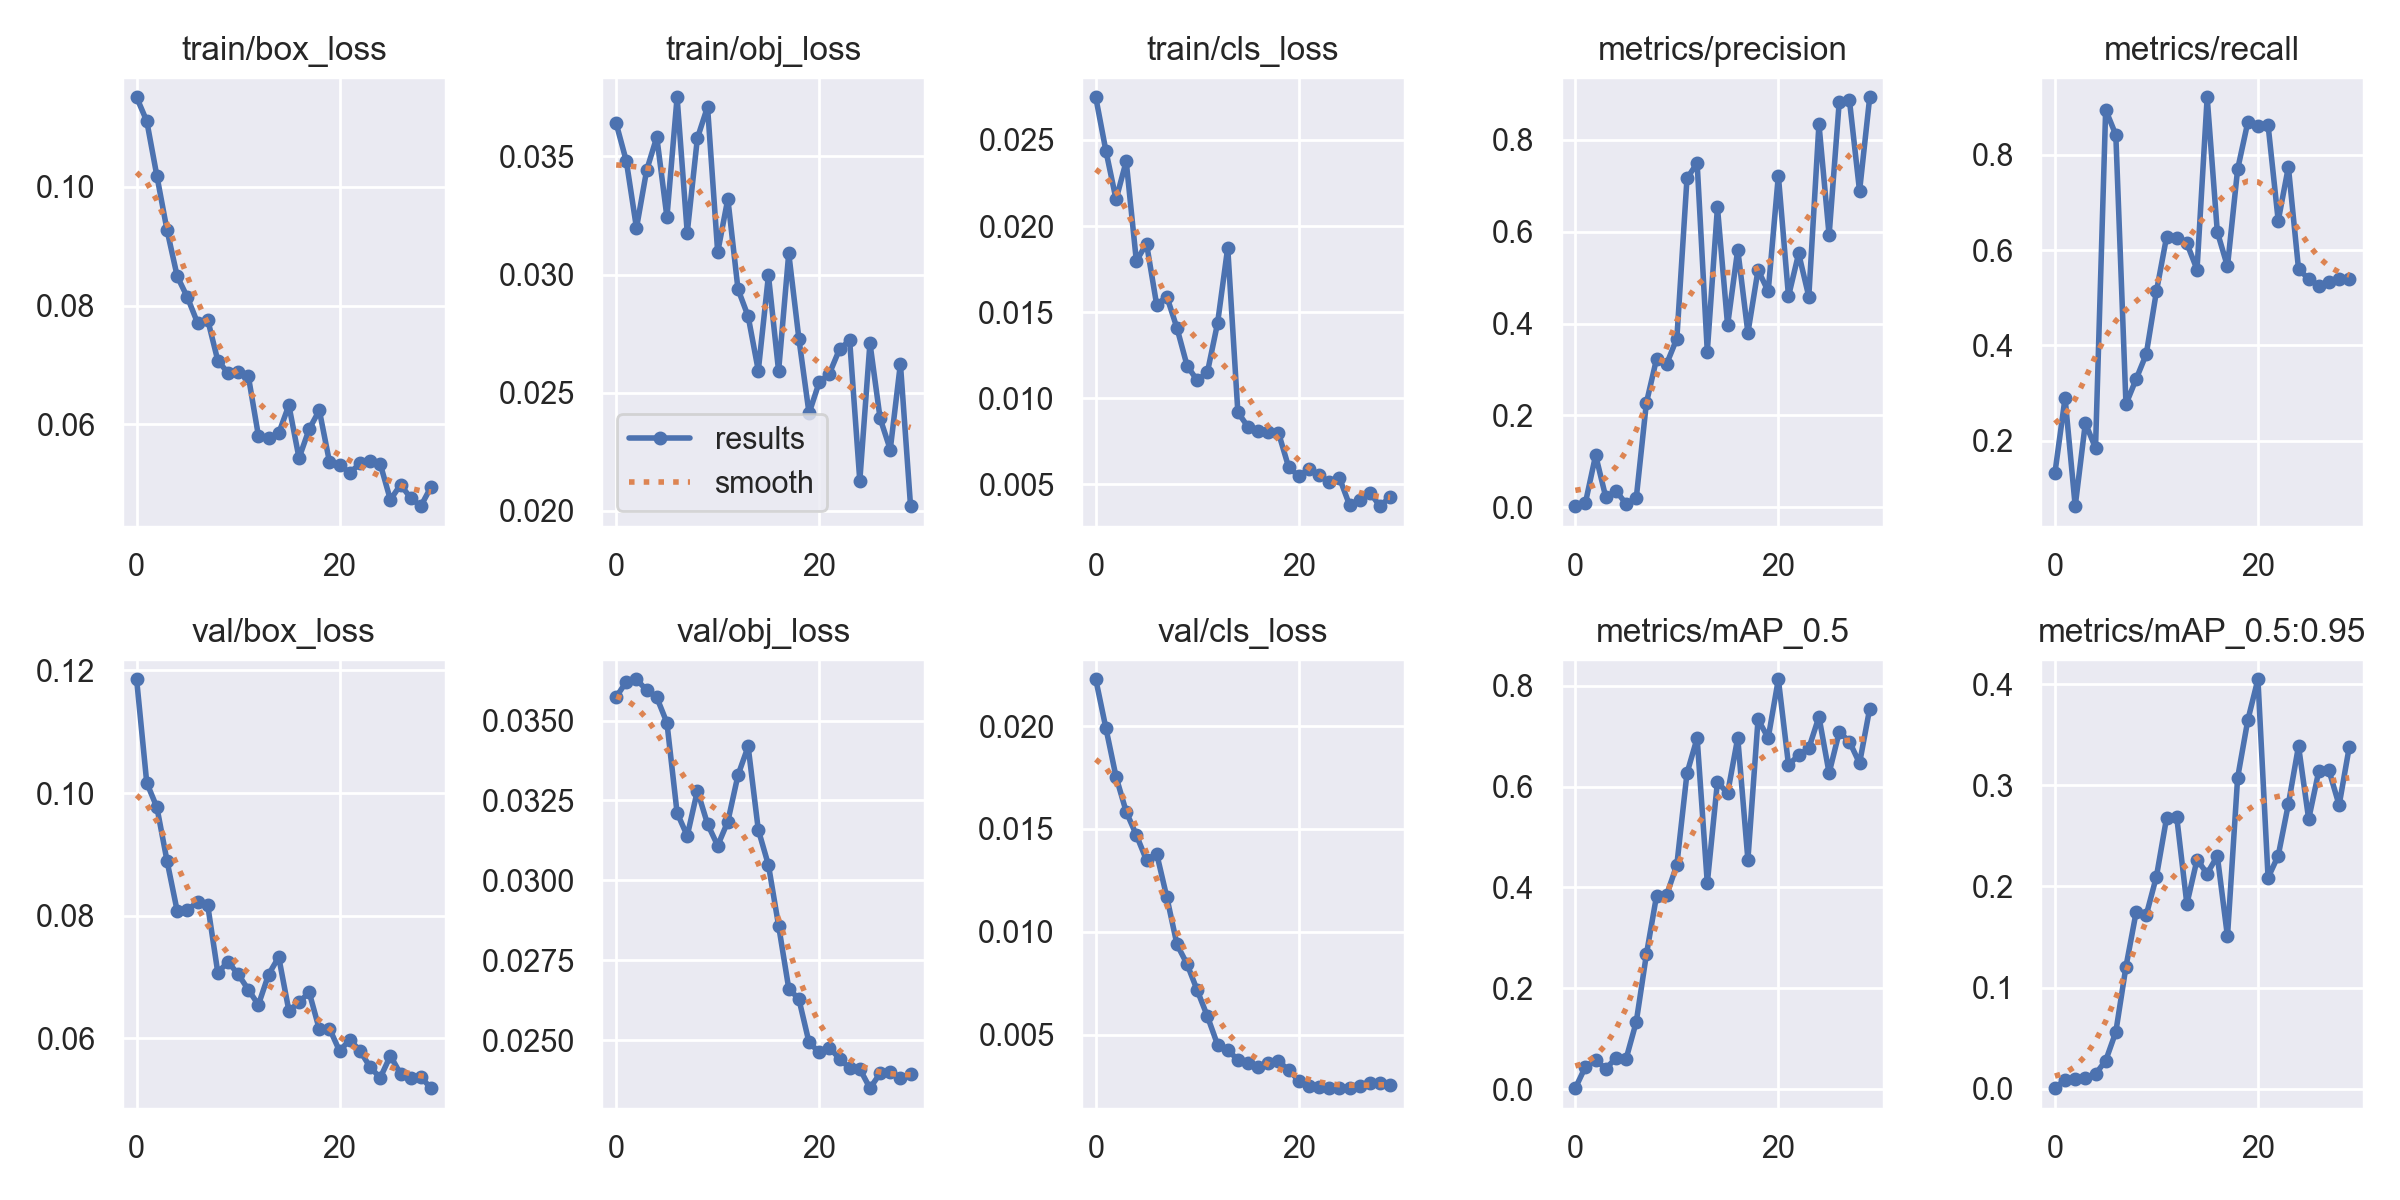

**60 épocas**

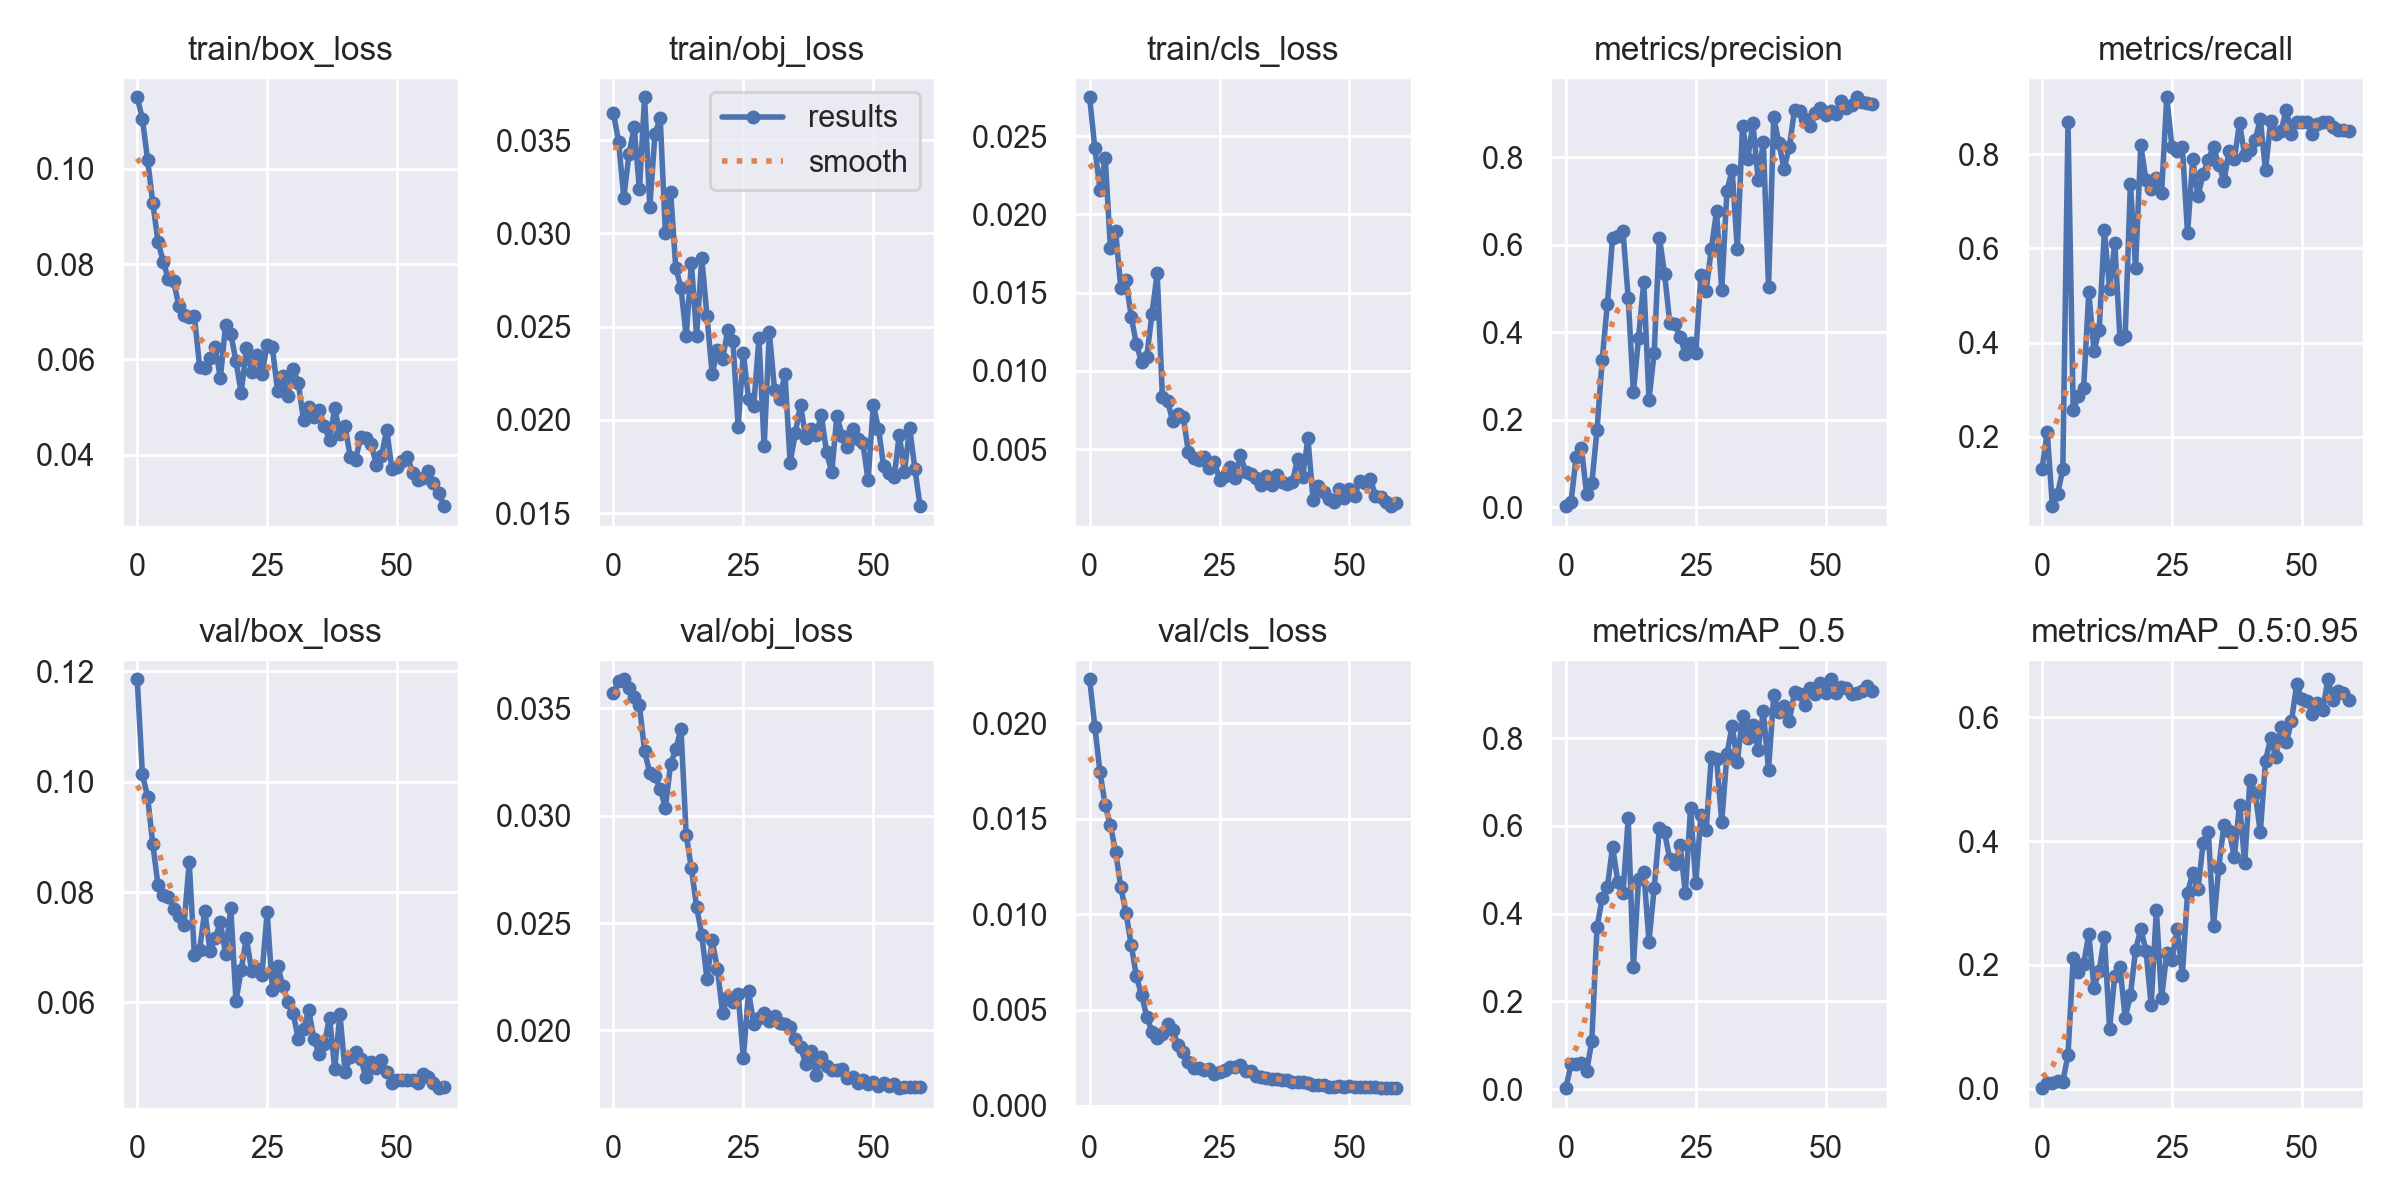

## 9. Escolher o modelo pela validação

O experimento de 60 épocas apresentou mAP@50–95 de **66,17%**, contra **41,23%** no de 30 épocas: aumento de **24,94 pontos percentuais**. A precisão também aumentou, enquanto o recall ficou próximo. A duração aumentou em aproximadamente 50 segundos.

Escolhemos o **`best.pt` do experimento de 60 épocas** para o teste final, usando apenas a comparação na validação. Como a validação contém 8 fotos, ela representa uma amostra pequena.

## 10. Avaliar no conjunto de teste

Agora avaliamos o modelo escolhido nas 8 fotos reservadas. O teste serve para relatar o resultado final; não foi usado para escolher a quantidade de épocas.

In [10]:
# Aproveita o código anterior, agora utilizando o conjunto de teste.
codigo_teste = (
    codigo_avaliacao
    .replace('task="val"', 'task="test"')
    .replace('name="validacao"', 'name="teste_final"')
    .replace('"metricas_validacao.json"', '"metricas_teste.json"')
)

# Avalia o melhor modelo do treinamento de 60 épocas.
subprocess.run(
    [sys.executable, "-c", codigo_teste, str(DATA), str(EXP60)],
    cwd=YOLO,
    check=True
)

metricas_teste = json.loads(
    (EXP60 / "metricas_teste.json").read_text()
)

resultado_teste = pd.DataFrame([{
    "Modelo": "YOLOv5s — 60 épocas",
    "Precisão (%)": metricas_teste["precisao"] * 100,
    "Recall (%)": metricas_teste["recall"] * 100,
    "mAP@50 (%)": metricas_teste["map50"] * 100,
    "mAP@50–95 (%)": metricas_teste["map50_95"] * 100
}])

resultado_teste.to_csv(
    RESULTADOS / "resultado_teste_yolo.csv",
    index=False
)

MODELO_ESCOLHIDO = EXP60 / "weights" / "best.pt"
TESTE = EXP60 / "teste_final"

print("\nRESULTADO FINAL NAS 8 IMAGENS DE TESTE:")
display(resultado_teste.round(2))
print("\nImagens e gráficos salvos em:", TESTE)


RESULTADO FINAL NAS 8 IMAGENS DE TESTE:


,Modelo,Precisão (%),Recall (%),mAP@50 (%),mAP@50–95 (%)
0,YOLOv5s — 60 épocas,90.87,72.92,83.74,55.63



Imagens e gráficos salvos em: /content/drive/MyDrive/FIAP_fase6_grupo21/resultados_yolo/exp_60_epocas_20261012_200853/teste_final


## 11. Interpretar o resultado do teste

O modelo escolhido apresentou **precisão de 90,87%**, **recall de 72,92%**, **mAP@50 de 83,74%** e **mAP@50–95 de 55,63%**.

O mAP@50–95 ficou 10,54 pontos percentuais abaixo da validação. O recall menor evidencia objetos marcados que não foram recuperados. Essa diferença, sozinha, não comprova sobreajuste.

A avaliação tem apenas 8 fotos e algumas contêm vários objetos. A análise visual complementa as métricas e ajuda a mostrar as situações em que o modelo falhou.


Marcações originais: o que o modelo deveria encontrar


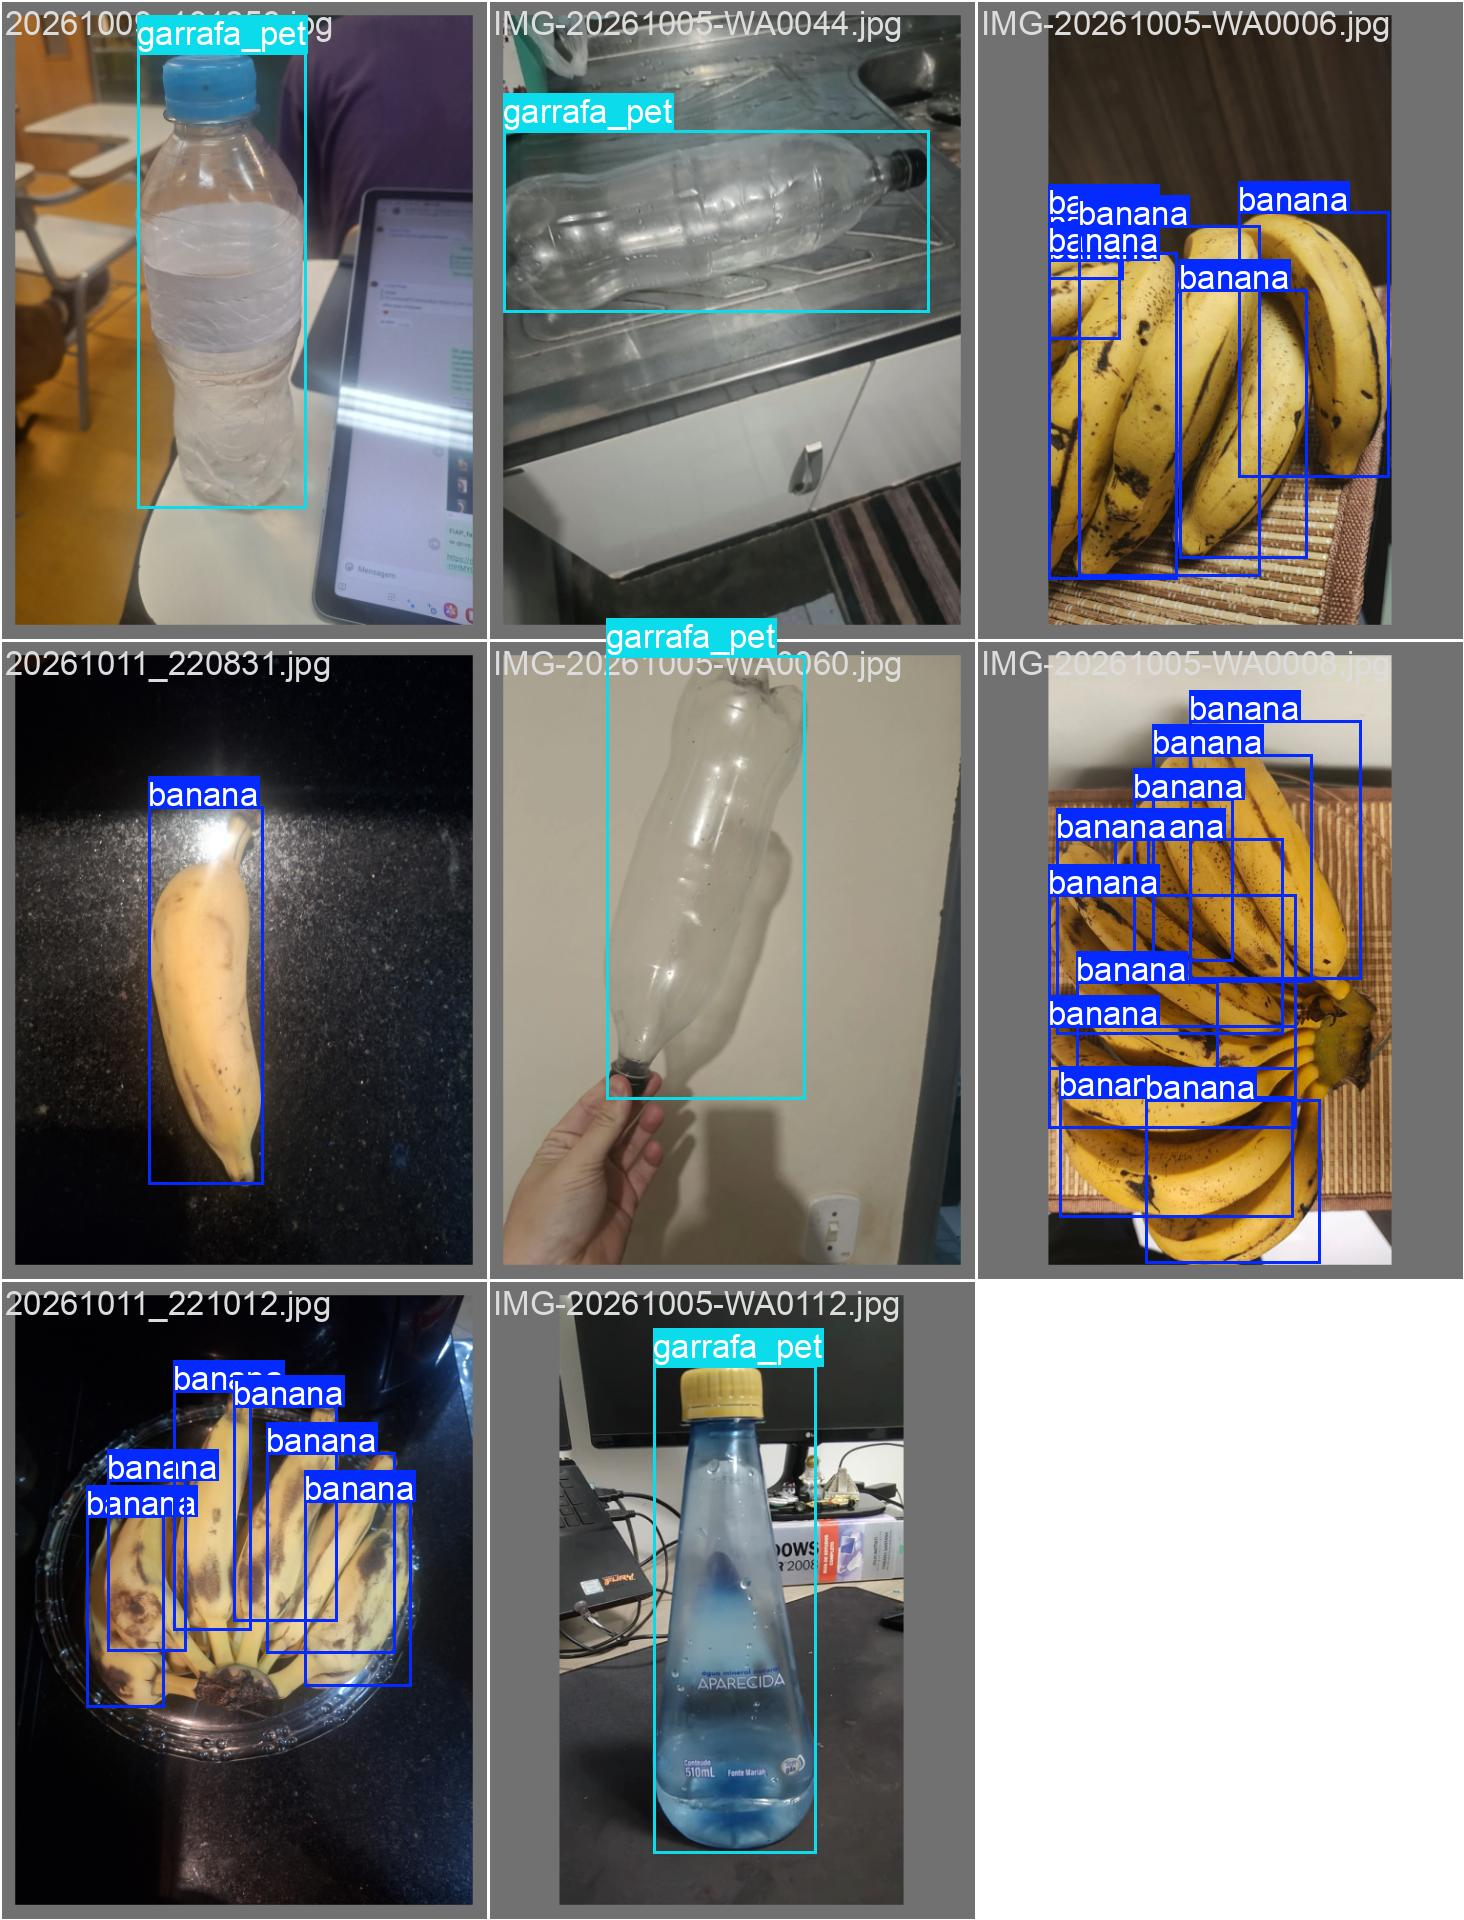


Previsões: o que o modelo encontrou


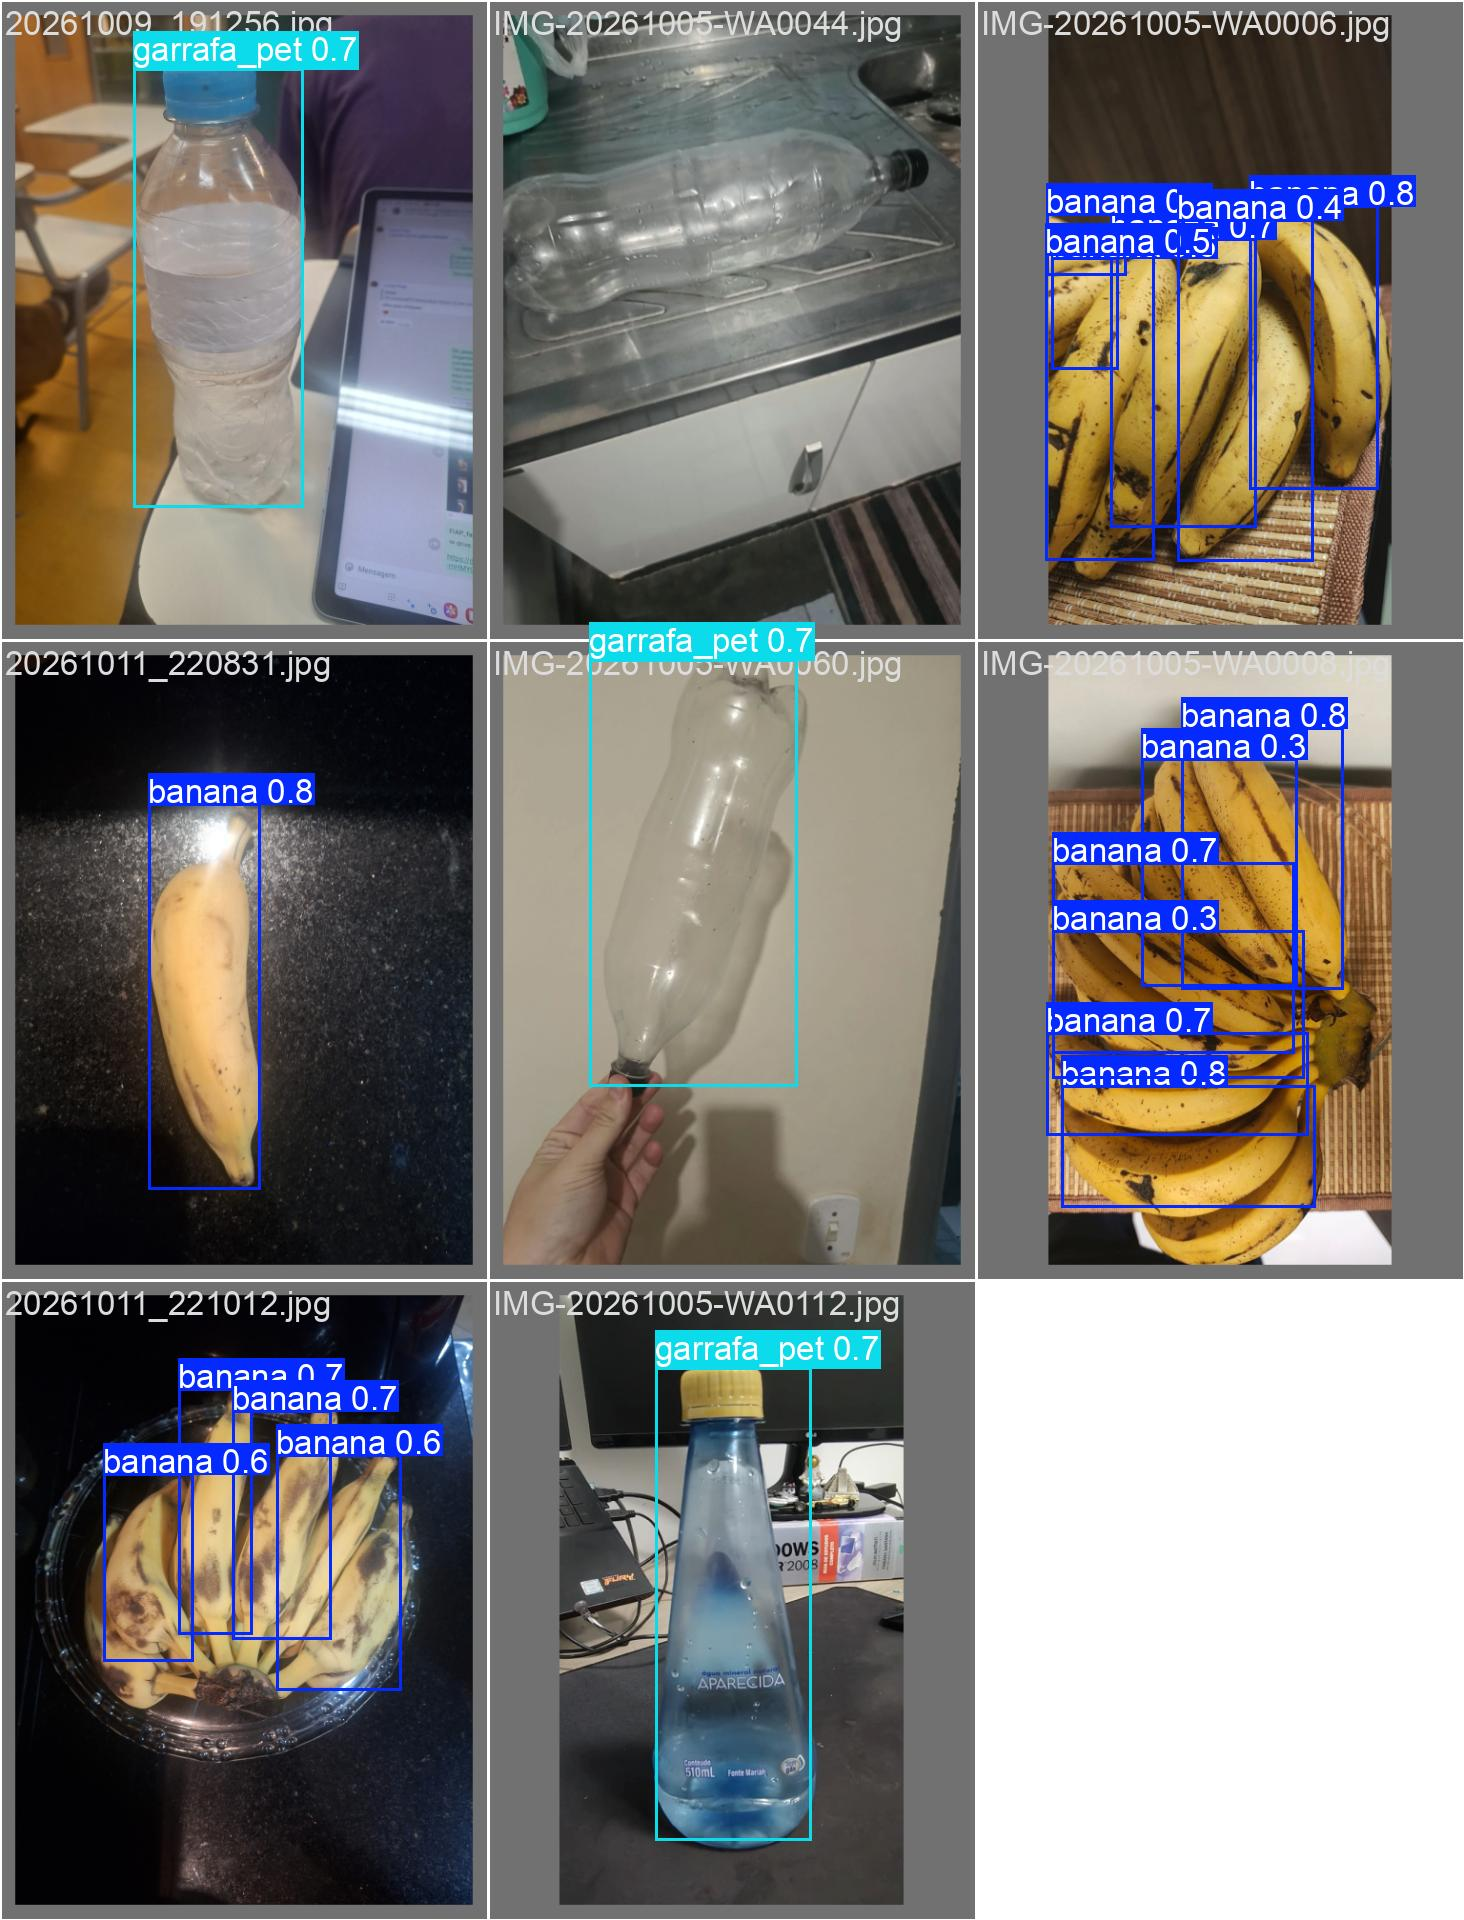


Matriz de confusão: resumo dos acertos e erros


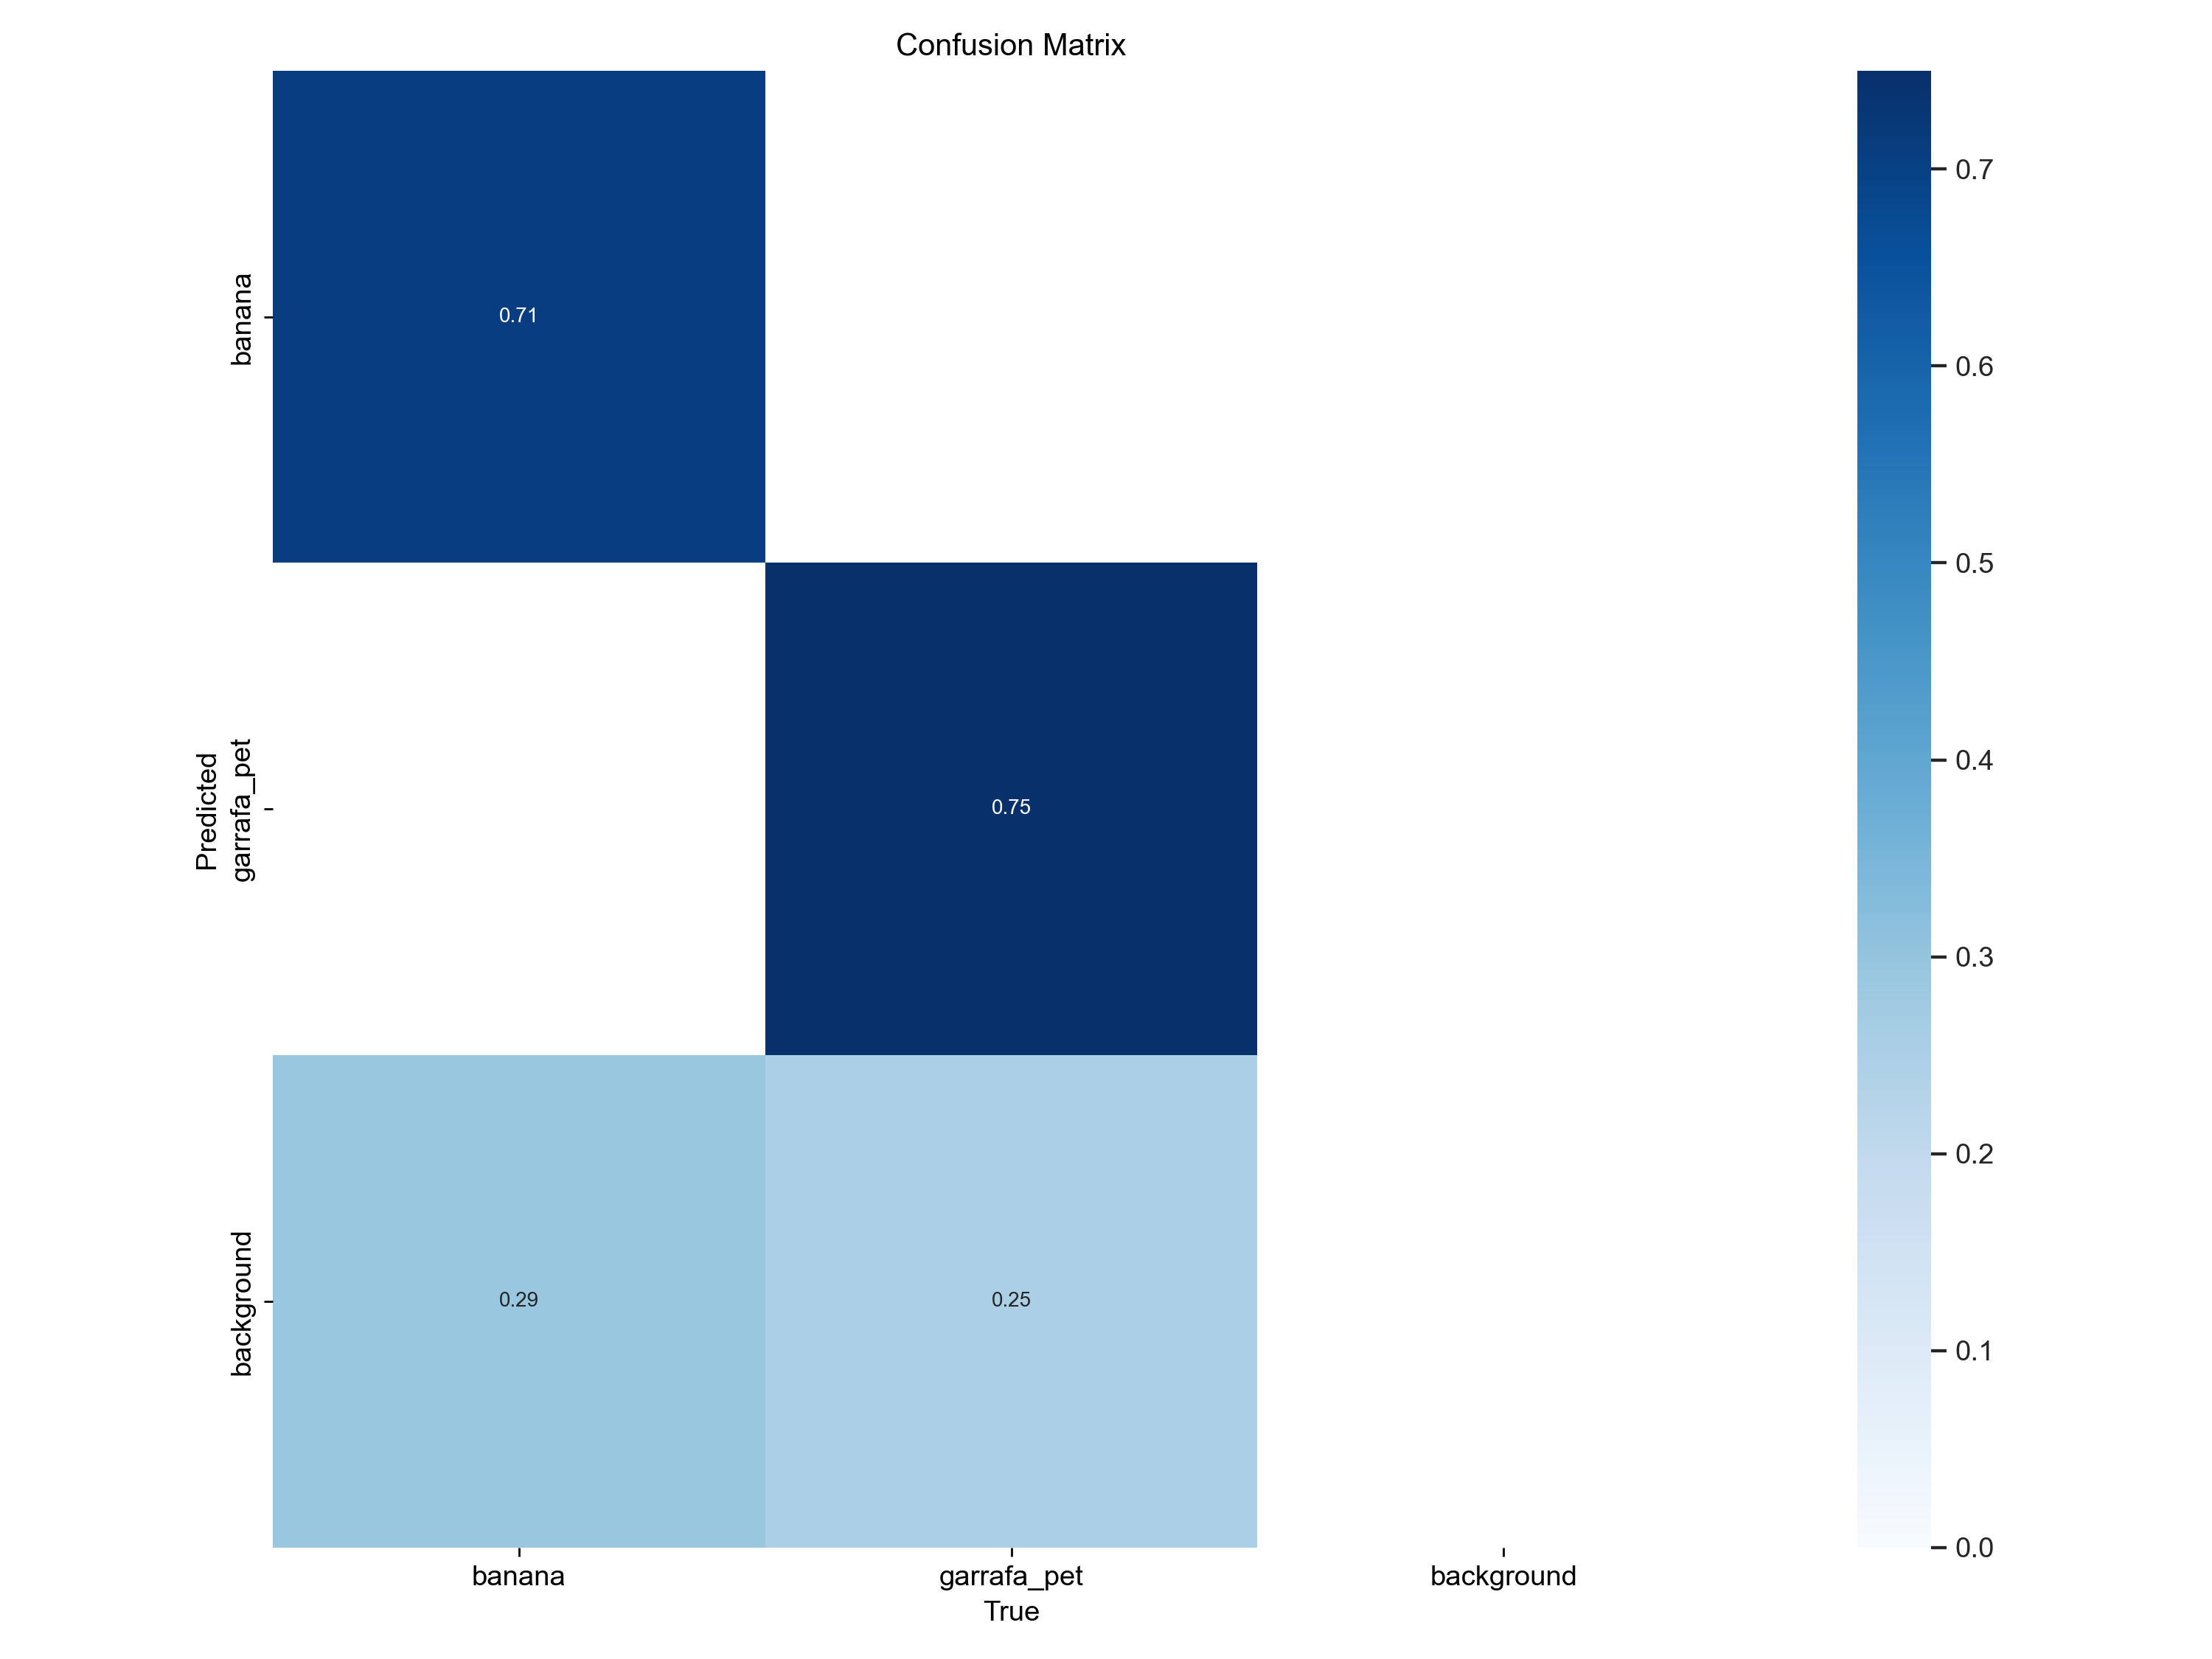

In [11]:
from IPython.display import Image as Imagem, display

# Mostra a referência, as previsões e o resumo dos erros.
arquivos = [
    ("Marcações originais: o que o modelo deveria encontrar",
     "val_batch0_labels.jpg"),

    ("Previsões: o que o modelo encontrou",
     "val_batch0_pred.jpg"),

    ("Matriz de confusão: resumo dos acertos e erros",
     "confusion_matrix.png")
]

for titulo, nome in arquivos:
    caminho = TESTE / nome
    print("\n" + titulo)

    if caminho.is_file():
        display(Imagem(filename=str(caminho), width=1000))
    else:
        print("Arquivo não encontrado:", caminho)

## 12. Analisar visualmente os acertos e erros

O modelo identificou exemplos de bananas e garrafas PET. A garrafa deitada na pia, na foto `IMG-20261005-WA0044.jpg`, ficou sem detecção nas previsões exibidas. Algumas bananas dos cachos também ficaram sem detecção correspondente às caixas de referência.

A matriz de confusão exibida considera **objetos e suas caixas**, e não o acerto da classe de cada foto. As colunas representam as classes reais; as linhas representam as previsões. A linha `background` reúne objetos marcados sem detecção correspondente, conforme os critérios usados pelo gráfico.

Não aparecem trocas entre banana e garrafa PET nessa matriz. Isso não garante ausência de confusão em outras imagens. O gráfico e o mAP usam critérios de avaliação distintos; seus números não devem ser interpretados como a mesma medida.

A sobreposição das bananas, os fundos e a iluminação são aspectos que podem ser investigados com mais fotos em trabalhos futuros.

## 13. Avaliar o acerto da classe por foto

Para apoiar a comparação com a CNN, verificamos se o modelo identifica a classe presente em cada foto. Usamos a detecção de maior confiança entre as duas classes, com confiança mínima de **0,25**. Fotos sem detecção contam como erro.

A confiança indica a pontuação de uma previsão. Ela não é o percentual de acerto do modelo no teste. A regra acima produz uma medida de classificação por foto; o mAP continua sendo necessário para avaliar as caixas dos objetos.

In [12]:
from datetime import datetime

# Gera previsões individuais e guarda o registro da execução.
NOME_PRED = "predicoes_por_foto_" + datetime.now().strftime("%Y%m%d_%H%M%S")
PREDICOES = EXP60 / NOME_PRED

execucao = subprocess.run(
    [
        sys.executable, str(YOLO / "detect.py"),
        "--weights", str(MODELO_ESCOLHIDO),
        "--source", str(LOCAL / "images" / "test"),
        "--imgsz", "640",
        "--conf-thres", "0.25",
        "--iou-thres", "0.60",
        "--max-det", "300",
        "--classes", "0", "1",
        "--device", "0",
        "--save-txt", "--save-conf",
        "--project", str(EXP60),
        "--name", NOME_PRED
    ],
    cwd=YOLO,
    text=True,
    capture_output=True
)

LOG_INFERENCIA = execucao.stdout + "\n" + execucao.stderr

if execucao.returncode != 0:
    print(LOG_INFERENCIA)
    execucao.check_returncode()

(PREDICOES / "log_inferencia.txt").write_text(
    LOG_INFERENCIA, encoding="utf-8"
)

# Compara a classe prevista com a classe marcada em cada foto.
classes = {0: "banana", 1: "garrafa_pet"}
linhas = []

for foto in sorted((LOCAL / "images" / "test").glob("*.jpg")):
    marcacao = LOCAL / "labels" / "test" / f"{foto.stem}.txt"
    classes_reais = {
        int(linha.split()[0])
        for linha in marcacao.read_text().splitlines()
        if linha.strip()
    }

    if len(classes_reais) != 1:
        raise ValueError(f"Rever as classes da foto: {foto.name}")

    esperado = next(iter(classes_reais))
    arquivo_pred = PREDICOES / "labels" / f"{foto.stem}.txt"
    deteccoes = []

    if arquivo_pred.is_file():
        deteccoes = [
            linha.split()
            for linha in arquivo_pred.read_text().splitlines()
            if linha.strip()
        ]

    previsto = (
        int(max(deteccoes, key=lambda d: float(d[-1]))[0])
        if deteccoes else None
    )

    linhas.append({
        "Foto": foto.name,
        "Esperado": classes[esperado],
        "Previsto": classes.get(previsto, "Sem detecção"),
        "Acertou": "Sim" if previsto == esperado else "Não"
    })

tabela_fotos = pd.DataFrame(linhas)
acertos = int((tabela_fotos["Acertou"] == "Sim").sum())
ACURACIA_FOTOS = 100 * acertos / len(tabela_fotos)

tabela_fotos.to_csv(PREDICOES / "acertos_por_foto.csv", index=False)

display(tabela_fotos)
print(f"\nResultado por foto: {acertos}/{len(tabela_fotos)}"
      f" = {ACURACIA_FOTOS:.2f}%")
print("Arquivos salvos em:", PREDICOES)

,Foto,Esperado,Previsto,Acertou
0,20261009_191256.jpg,garrafa_pet,garrafa_pet,Sim
1,20261011_220831.jpg,banana,banana,Sim
2,20261011_221012.jpg,banana,banana,Sim
3,IMG-20261005-WA0006.jpg,banana,banana,Sim
4,IMG-20261005-WA0008.jpg,banana,banana,Sim
5,IMG-20261005-WA0044.jpg,garrafa_pet,Sem detecção,Não
6,IMG-20261005-WA0060.jpg,garrafa_pet,garrafa_pet,Sim
7,IMG-20261005-WA0112.jpg,garrafa_pet,garrafa_pet,Sim



Resultado por foto: 7/8 = 87.50%
Arquivos salvos em: /content/drive/MyDrive/FIAP_fase6_grupo21/resultados_yolo/exp_60_epocas_20261012_200853/predicoes_por_foto_20261012_210135


## 14. Interpretar o acerto por foto

O modelo acertou a classe de **7 das 8 fotos**, obtendo **87,50% de acerto** e **12,50% de erro** por foto. Houve 4 acertos nas 4 fotos de banana e 3 nas 4 fotos de garrafa PET.

O único erro foi `IMG-20261005-WA0044.jpg`, que ficou sem detecção. Nas fotos corretamente classificadas como banana, ainda houve objetos individuais sem detecção correspondente. Acertar a classe da foto não significa encontrar todos os objetos presentes.

Um erro adicional neste teste altera o acerto global em 12,50 pontos percentuais. Elton poderá comparar esse critério com a YOLO padrão e a CNN usando as mesmas 8 fotos.

## 15. Medir o tempo de inferência

Extraímos as médias do registro de `detect.py` na execução das 8 fotos, após o aquecimento interno da rotina. Foi usado lote de uma imagem, GPU Tesla T4, precisão FP32 (`half=False`) e tamanho configurado 640. O registro mostra entradas retangulares de 640×480 ou 640×384, conforme a proporção da foto.

O programa mede separadamente a preparação do tensor, o cálculo da rede e a filtragem de caixas repetidas (NMS). A medição não inclui todas as etapas de leitura e redimensionamento da foto, carregamento do modelo ou gravação das previsões. Portanto, 17,30 ms representa o cálculo da rede, e não a resposta completa de uma aplicação.

Esta medição foi feita em uma execução pequena. A comparação com os colegas deve registrar o dispositivo, a resolução, o lote e as etapas incluídas. Referência: [rotina oficial de inferência do YOLOv5 na versão utilizada](https://github.com/ultralytics/yolov5/blob/f9578796b8a64889aa9e66dc06914d19f40d338e/detect.py).

In [13]:
import re
import torch

padrao = (
    r"Speed:\s*([\d.]+)ms pre-process,\s*"
    r"([\d.]+)ms inference,\s*([\d.]+)ms NMS"
)
medicao = re.search(padrao, LOG_INFERENCIA)

if medicao is None:
    print(LOG_INFERENCIA)
    raise ValueError("Não foi possível localizar os tempos no registro.")

preparacao_ms, modelo_ms, filtragem_ms = map(float, medicao.groups())

tempos = {
    "preparacao_medida_ms_por_foto": preparacao_ms,
    "inferencia_modelo_ms_por_foto": modelo_ms,
    "filtragem_caixas_ms_por_foto": filtragem_ms,
    "fotos_avaliadas": len(tabela_fotos),
    "gpu": torch.cuda.get_device_name(0),
    "batch_size": 1,
    "imgsz": 640
}

(PREDICOES / "tempos_inferencia.json").write_text(
    json.dumps(tempos, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print(f"Preparação da entrada: {preparacao_ms:.2f} ms por foto")
print(f"Análise pelo modelo: {modelo_ms:.2f} ms por foto")
print(f"Filtragem das caixas: {filtragem_ms:.2f} ms por foto")
print("GPU utilizada:", tempos["gpu"])
print("Tempos salvos no Drive.")

Preparação da entrada: 0.50 ms por foto
Análise pelo modelo: 17.30 ms por foto
Filtragem das caixas: 21.40 ms por foto
GPU utilizada: Tesla T4
Tempos salvos no Drive.


## 16. Conclusão da YOLO customizada

O experimento de 60 épocas apresentou o melhor resultado na validação e foi escolhido para o teste final. No teste, alcançou mAP@50–95 de **55,63%** e acertou a classe de **7 das 8 fotos (87,50%)**.

Os pontos fortes são a identificação das duas classes com uma base pequena, a geração de caixas e a organização das evidências. O fluxo depende de preparar o ambiente, montar o Drive, conferir as marcações e configurar os caminhos. Essa preparação exigiu trabalho adicional, mas permitiu aproveitar pesos pré-treinados e completar os experimentos em poucos minutos.

As principais limitações são a garrafa deitada na pia sem detecção, bananas dos cachos sem detecção correspondente, as 8 fotos de teste e a ausência de um ambiente com todas as dependências congeladas. Os resultados sustentam uma demonstração acadêmica; a capacidade de generalização precisa ser avaliada com mais diversidade de imagens.

O tempo médio de cálculo do modelo foi de **17,30 ms por foto** na Tesla T4. As outras etapas medidas foram 0,50 ms de preparação e 21,40 ms de filtragem. Esses valores correspondem a uma execução nas 8 fotos e não ao tempo completo de uma aplicação.

Para a Entrega 2, esta contribuição fornece as métricas de detecção, a classificação por foto, as durações e os arquivos de inferência. A comparação das três abordagens deve considerar a mesma base, as diferenças entre classificar e detectar e as condições de medição.

## 17. Arquivos produzidos e integração

Todos os resultados desta execução estão em `FIAP_fase6_grupo21/resultados_yolo` no Drive:

| Conteúdo | Pasta ou arquivo |
| --- | --- |
| Experimento de 30 épocas | `exp_30_epocas_20261012_194929` |
| Experimento de 60 épocas | `exp_60_epocas_20261012_200853` |
| Modelo escolhido | `exp_60_epocas_20261012_200853/weights/best.pt` |
| Teste de detecção e gráficos | `exp_60_epocas_20261012_200853/teste_final` |
| Previsões individuais, acertos e tempos | `exp_60_epocas_20261012_200853/predicoes_por_foto_20261012_210135` |
| Comparação na validação | `comparacao_validacao_yolo.csv` |
| Métricas do teste | `resultado_teste_yolo.csv` |

O GitHub preserva uma cópia dos CSVs, JSONs, configurações e gráficos relevantes em `docs/resultados/frente1_yolo` e `docs/figuras/frente1_yolo`. Imagens originais e pesos permanecem no Drive. O [resumo para integração](https://github.com/lucas-crvlh/fase6-cap1-farmtech/blob/main/docs/RESULTADOS_FRENTE1.md) informa o protocolo usado para apoiar a comparação.

A integração final ainda precisa reunir a YOLO padrão, a CNN do zero, a comparação crítica das três abordagens e o vídeo. O notebook consolidado também deve identificar os quatro integrantes com nome completo e RM.